# Machine Learning – Practical Session 2
**National Higher School of Advanced Technologies – 2026/2027 – First-year Master**

**Standardized PCA: from scratch vs Scikit-learn**

Name: ____________________  Group: ________

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

pd.set_option("display.precision", 4)
pd.set_option("display.width", 120)

## Part A: Standardized PCA from scratch

### 1. Load the dataset

In [2]:
data = {
    "Student": ["S1", "S2", "S3", "S4", "S5", "S6"],
    "Mathematics": [12, 15, 8, 17, 10, 14],
    "Statistics": [11, 14, 9, 16, 12, 15],
    "Programming": [14, 16, 10, 18, 11, 13],
    "Algorithms": [13, 15, 9, 17, 10, 14],
}
df = pd.DataFrame(data).set_index("Student")
df

,Mathematics,Statistics,Programming,Algorithms
Student,,,,
S1,12,11,14,13
S2,15,14,16,15
S3,8,9,10,9
S4,17,16,18,17
S5,10,12,11,10
S6,14,15,13,14


### 2. Dimensions and descriptive statistics

In [3]:
print("Shape:", df.shape, "-> 6 students, 4 subjects")
df.describe()

Shape: (6, 4) -> 6 students, 4 subjects


,Mathematics,Statistics,Programming,Algorithms
count,6.0000,6.0000,6.0000,6.0000
mean,12.6667,12.8333,13.6667,13.0000
std,3.3267,2.6394,3.0111,3.0332
min,8.0000,9.0000,10.0000,9.0000
25%,10.5000,11.2500,11.5000,10.7500
50%,13.0000,13.0000,13.5000,13.5000
75%,14.7500,14.7500,15.5000,14.7500
max,17.0000,16.0000,18.0000,17.0000


### 3. Standardization  z = (x − mean) / std  (sample std, n − 1)

In [4]:
X = df.values.astype(float)
mean = X.mean(axis=0)
std = X.std(axis=0, ddof=1)
Z = (X - mean) / std

pd.DataFrame(Z, index=df.index, columns=df.columns)

,Mathematics,Statistics,Programming,Algorithms
Student,,,,
S1,-0.2004,-0.6946,0.1107,0.0000
S2,0.7014,0.4420,0.7749,0.6594
S3,-1.4028,-1.4523,-1.2177,-1.3188
S4,1.3026,1.1997,1.4391,1.3188
S5,-0.8016,-0.3157,-0.8856,-0.9891
S6,0.4008,0.8209,-0.2214,0.3297


### 4. Correlation matrix of the standardized data

In [5]:
corr = np.corrcoef(Z, rowvar=False)
pd.DataFrame(corr, index=df.columns, columns=df.columns)

,Mathematics,Statistics,Programming,Algorithms
Mathematics,1.0000,0.9263,0.9451,0.9911
Statistics,0.9263,1.0000,0.7717,0.8744
Programming,0.9451,0.7717,1.0000,0.9635
Algorithms,0.9911,0.8744,0.9635,1.0000


All correlations are positive and high (0.77 to 0.99): a student good in one subject tends to be good in the others.

### 5. Eigenvalues and eigenvectors (covariance matrix of the standardized data = correlation matrix)

In [6]:
cov_Z = np.cov(Z, rowvar=False)
eigvals, eigvecs = np.linalg.eigh(cov_Z)
print("Eigenvalues (unsorted):", eigvals)

Eigenvalues (unsorted): [9.27120965e-04 1.91170901e-02 2.40228481e-01 3.73972731e+00]


### 6. Sort in descending order

In [7]:
idx = np.argsort(eigvals)[::-1]
eigvals = eigvals[idx]
eigvecs = eigvecs[:, idx]

print("Eigenvalues:", eigvals)
print("Sum of eigenvalues:", eigvals.sum(), "(= number of variables)")
pd.DataFrame(eigvecs, index=df.columns, columns=["PC1", "PC2", "PC3", "PC4"])

Eigenvalues: [3.73972731e+00 2.40228481e-01 1.91170901e-02 9.27120965e-04]
Sum of eigenvalues: 4.0 (= number of variables)


,PC1,PC2,PC3,PC4
Mathematics,-0.5167,0.0320,0.2093,0.8296
Statistics,-0.4770,0.7822,-0.3149,-0.2478
Programming,-0.4928,-0.5922,-0.6249,-0.1264
Algorithms,-0.5125,-0.1909,0.6830,-0.4841


### 7. Select the two eigenvectors with the largest eigenvalues

In [8]:
W = eigvecs[:, :2]
pd.DataFrame(W, index=df.columns, columns=["PC1", "PC2"])

,PC1,PC2
Mathematics,-0.5167,0.0320
Statistics,-0.4770,0.7822
Programming,-0.4928,-0.5922
Algorithms,-0.5125,-0.1909


### 8. Projection on the two principal components

In [9]:
scores_scratch = Z @ W
pd.DataFrame(scores_scratch, index=df.index, columns=["PC1", "PC2"])

,PC1,PC2
Student,,
S1,0.3803,-0.6153
S2,-1.2930,-0.2166
S3,2.6935,-0.2080
S4,-2.6304,-0.1239
S5,1.5081,0.4407
S6,-0.6585,0.7231


### 9. Explained variance ratio and cumulative explained variance

In [10]:
ratio_scratch = eigvals / eigvals.sum()
cum_scratch = np.cumsum(ratio_scratch)

pd.DataFrame({"Eigenvalue": eigvals,
              "Explained ratio": ratio_scratch,
              "Cumulative": cum_scratch},
             index=["PC1", "PC2", "PC3", "PC4"])

,Eigenvalue,Explained ratio,Cumulative
PC1,3.7397,0.9349,0.9349
PC2,0.2402,0.0601,0.9950
PC3,0.0191,0.0048,0.9998
PC4,0.0009,0.0002,1.0000


## Part B: Standardized PCA using Scikit-learn

### 10-11. PCA with 2 components

In [11]:
pca = PCA(n_components=2)
scores_sk = pca.fit_transform(Z)

### 12. Transformed coordinates of the students

In [12]:
pd.DataFrame(scores_sk, index=df.index, columns=["PC1", "PC2"])

,PC1,PC2
Student,,
S1,-0.3803,-0.6153
S2,1.2930,-0.2166
S3,-2.6935,-0.2080
S4,2.6304,-0.1239
S5,-1.5081,0.4407
S6,0.6585,0.7231


### 13. Explained variance ratio and cumulative explained variance

In [13]:
eigvals_sk = pca.explained_variance_
ratio_sk = pca.explained_variance_ratio_
cum_sk = np.cumsum(ratio_sk)

pd.DataFrame({"Eigenvalue": eigvals_sk,
              "Explained ratio": ratio_sk,
              "Cumulative": cum_sk},
             index=["PC1", "PC2"])

,Eigenvalue,Explained ratio,Cumulative
PC1,3.7397,0.9349,0.9349
PC2,0.2402,0.0601,0.9950


## Part C: Comparison and interpretation

### 14. Compare the coordinates

In [14]:
pd.DataFrame({
    "PC1 scratch": scores_scratch[:, 0], "PC1 sklearn": scores_sk[:, 0],
    "PC2 scratch": scores_scratch[:, 1], "PC2 sklearn": scores_sk[:, 1]},
    index=df.index)

,PC1 scratch,PC1 sklearn,PC2 scratch,PC2 sklearn
Student,,,,
S1,0.3803,-0.3803,-0.6153,-0.6153
S2,-1.2930,1.2930,-0.2166,-0.2166
S3,2.6935,-2.6935,-0.2080,-0.2080
S4,-2.6304,2.6304,-0.1239,-0.1239
S5,1.5081,-1.5081,0.4407,0.4407
S6,-0.6585,0.6585,0.7231,0.7231


In [15]:
signs = []
for k in range(2):
    s = np.sign(np.dot(scores_scratch[:, k], scores_sk[:, k]))
    signs.append(s)
    print(f"PC{k+1}:", "same sign" if s > 0 else "opposite sign")

aligned = scores_scratch * np.array(signs)
print("\nMax absolute difference after sign correction:",
      np.abs(aligned - scores_sk).max())

PC1: opposite sign
PC2: same sign

Max absolute difference after sign correction: 2.275957200481571e-15


### 15. Compare eigenvalues and explained variance ratios

In [16]:
pd.DataFrame({
    "Eigenvalue scratch": eigvals[:2], "Eigenvalue sklearn": eigvals_sk,
    "Ratio scratch": ratio_scratch[:2], "Ratio sklearn": ratio_sk,
    "Cumul. scratch": cum_scratch[:2], "Cumul. sklearn": cum_sk},
    index=["PC1", "PC2"]).T

,PC1,PC2
Eigenvalue scratch,3.7397,0.2402
Eigenvalue sklearn,3.7397,0.2402
Ratio scratch,0.9349,0.0601
Ratio sklearn,0.9349,0.0601
Cumul. scratch,0.9349,0.9950
Cumul. sklearn,0.9349,0.9950


### 16. Plot the students with both implementations

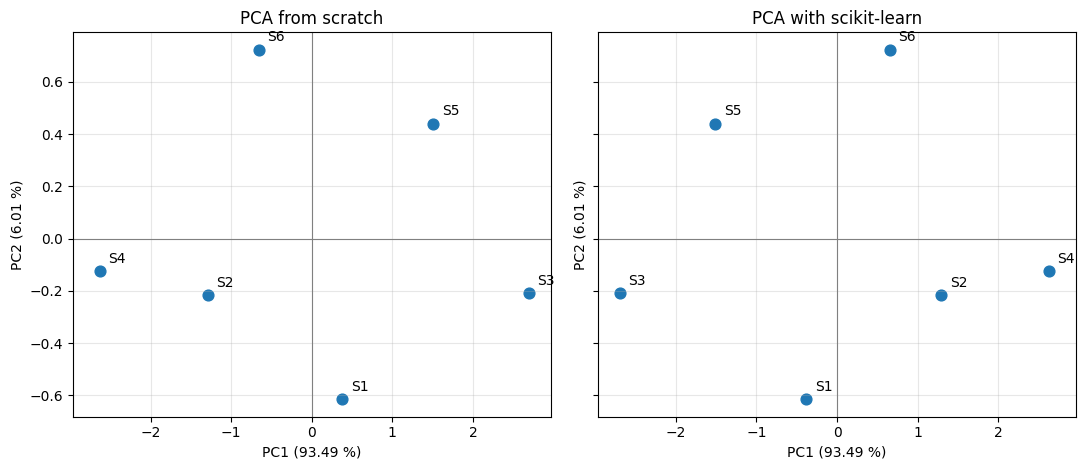

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharex=True, sharey=True)
for ax, sc, title in zip(axes, [scores_scratch, scores_sk],
                         ["PCA from scratch", "PCA with scikit-learn"]):
    ax.scatter(sc[:, 0], sc[:, 1], color="tab:blue", s=60)
    for name, (x, y) in zip(df.index, sc):
        ax.annotate(name, (x, y), textcoords="offset points", xytext=(6, 6))
    ax.axhline(0, color="grey", lw=0.8)
    ax.axvline(0, color="grey", lw=0.8)
    ax.set_title(title)
    ax.set_xlabel(f"PC1 ({ratio_scratch[0]*100:.2f} %)")
    ax.set_ylabel(f"PC2 ({ratio_scratch[1]*100:.2f} %)")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("students_pca_comparison.png", dpi=150)
plt.show()

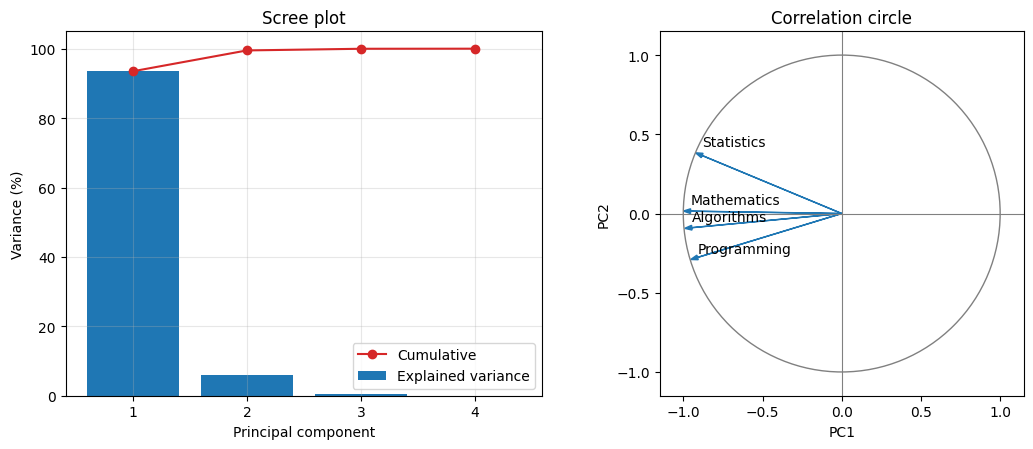

In [18]:
# Extra: scree plot and correlation circle
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))

axes[0].bar(range(1, 5), ratio_scratch * 100, color="tab:blue", label="Explained variance")
axes[0].plot(range(1, 5), cum_scratch * 100, "o-", color="tab:red", label="Cumulative")
axes[0].set_xticks(range(1, 5))
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Variance (%)")
axes[0].set_title("Scree plot")
axes[0].legend()
axes[0].grid(alpha=0.3)

load = W * np.sqrt(eigvals[:2])
for name, (x, y) in zip(df.columns, load):
    axes[1].arrow(0, 0, x, y, head_width=0.03, color="tab:blue", length_includes_head=True)
    axes[1].annotate(name, (x, y), textcoords="offset points", xytext=(5, 5))
axes[1].add_patch(plt.Circle((0, 0), 1, fill=False, color="grey"))
axes[1].set_xlim(-1.15, 1.15); axes[1].set_ylim(-1.15, 1.15)
axes[1].axhline(0, color="grey", lw=0.8); axes[1].axvline(0, color="grey", lw=0.8)
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
axes[1].set_title("Correlation circle")
axes[1].set_aspect("equal")
plt.tight_layout()
plt.savefig("scree_and_circle.png", dpi=150)
plt.show()

### 17. Explanation of the differences (sign change)

The eigenvalues, the explained variance and the coordinates are the same in both implementations, except that **PC1 has the opposite sign** (PC2 has the same sign).

An eigenvector is defined up to a sign: if *v* is an eigenvector of the correlation matrix for the eigenvalue λ, then *−v* is also one. `np.linalg.eigh` returns one of the two without any rule, while scikit-learn uses an SVD and then applies a sign convention (`svd_flip`). The sign does not change the explained variance, the distances between the students or the interpretation: the plot is only a mirror image along PC1. After multiplying the scratch PC1 by −1 the difference is about 1e-15 (rounding error).

**Remark:** `StandardScaler` divides by *n* instead of *n − 1*. In that case the eigenvalues are multiplied by 5/6 and the coordinates by √(5/6), but the explained variance ratios stay the same. We used the same standardized data Z in both parts to compare directly.

### 18. Percentage of total variance retained by the first two components

In [19]:
print(f"PC1 + PC2 retain {cum_scratch[1]*100:.2f} % of the total variance")
print(f"Information lost: {100 - cum_scratch[1]*100:.2f} %")

PC1 + PC2 retain 99.50 % of the total variance
Information lost: 0.50 %


## Interpretation of the findings

- **PC1 (93.49 %)** is a "general level" axis. The four loadings are almost equal (about 0.5 in absolute value) and the correlations with the variables are all above 0.92. Students with a high overall level (S4, S2) are at one end and the weakest (S3, S5) at the other end (the side depends on the sign convention).
- **PC2 (6.01 %)** is a contrast between Statistics and Programming. S6 is better in Statistics (15) than in Programming (13), S1 is the opposite (11 vs 14), so they are at opposite sides of PC2.
- **PC1 + PC2 keep 99.50 %** of the variance, so reducing from 4 to 2 dimensions loses only 0.50 %.
- The grades are almost one-dimensional: one component (overall performance) already summarizes more than 93 % of the information.

## Conclusion
The from-scratch PCA and scikit-learn give the same eigenvalues, explained variance and student configuration, up to the sign of PC1.